# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import TreeSatAIDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/TreeSatAI/aerial/",
    "csv_file": "./data/TreeSatAI/train_filenames.lst",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = TreeSatAIDataset(dataset_config)

## Show images from the dataset

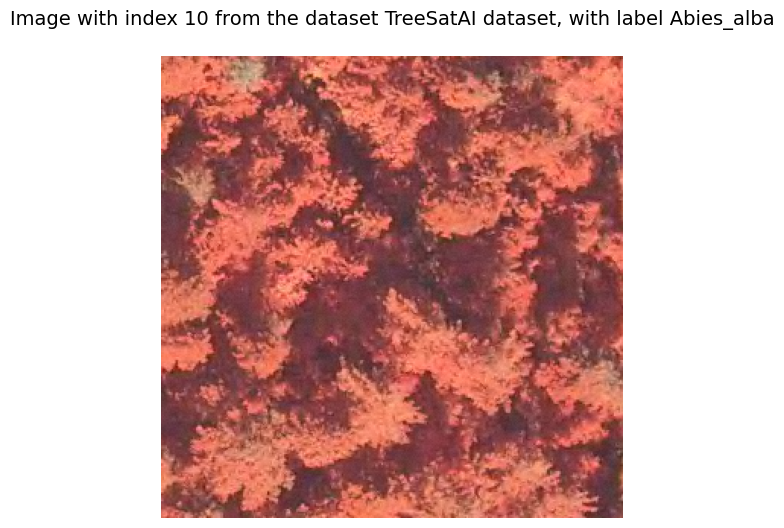

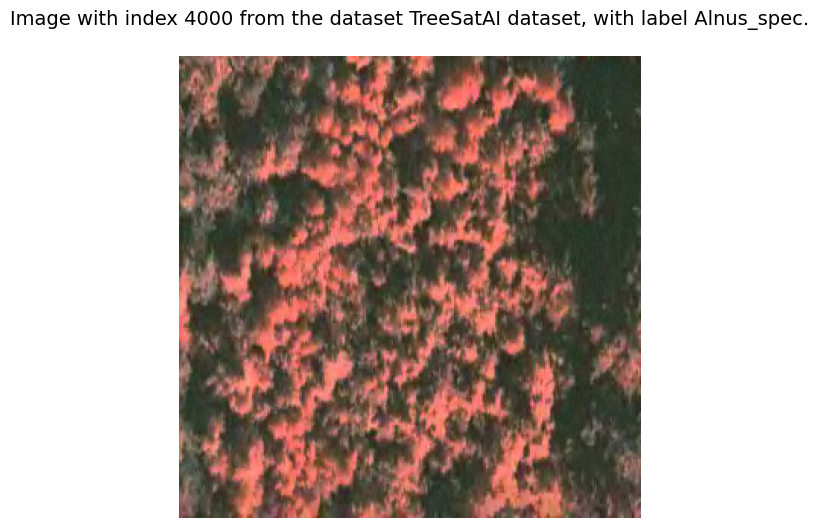

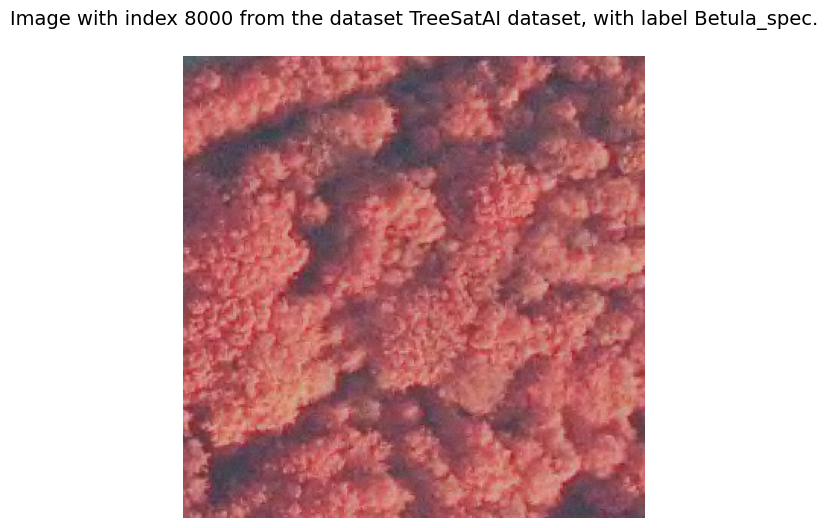

In [30]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(4000)
fig3 = dataset.show_image(8000)

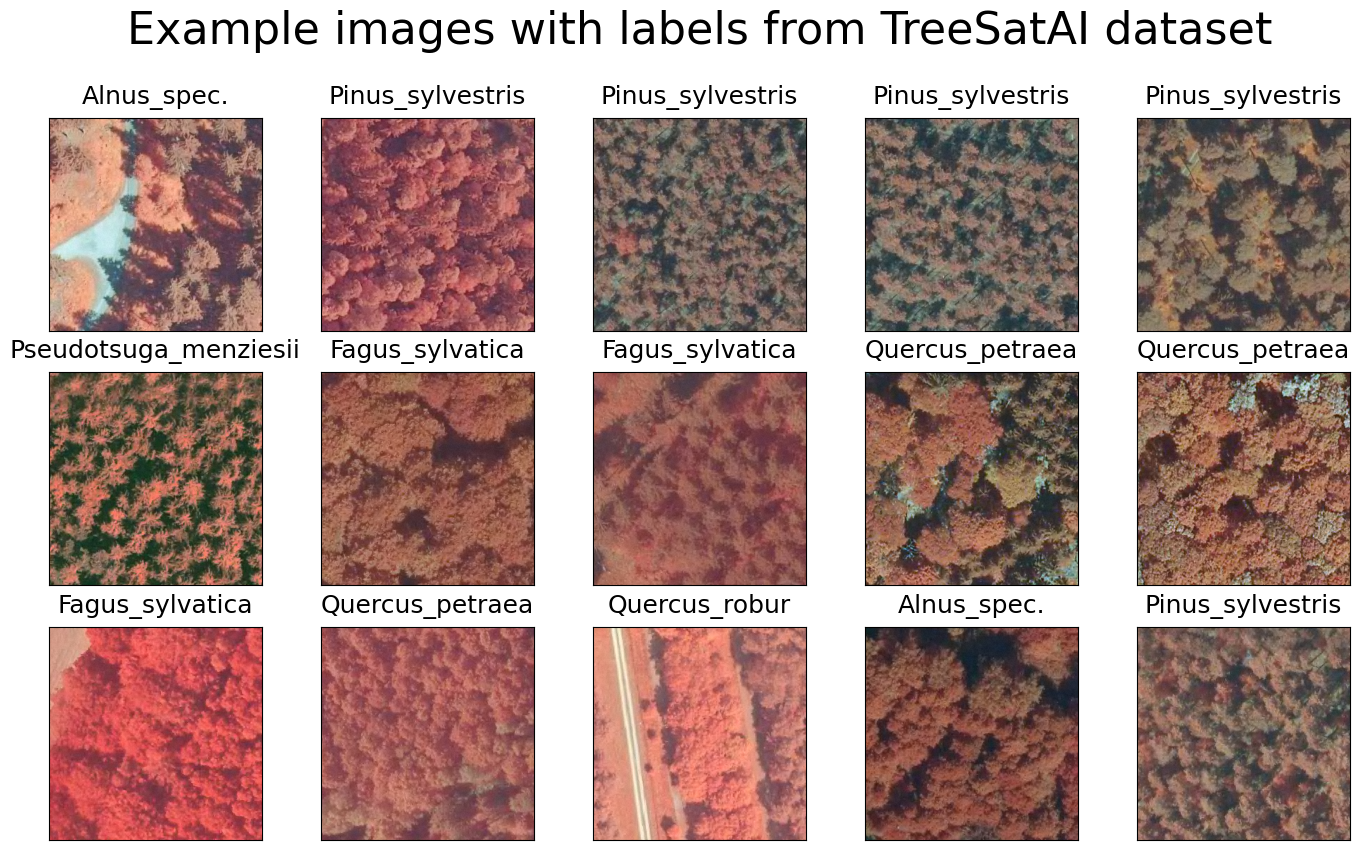

In [31]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [23]:
dataset.data_distribution_table()

,Label,Count
0,Abies_alba,891
1,Acer_pseudoplatanus,2539
2,Alnus_spec.,2316
3,Betula_spec.,2540
4,Cleared,3701
5,Fagus_sylvatica,5820
6,Fraxinus_excelsior,2379
7,Larix_decidua,1228
8,Larix_kaempferi,1564
9,Picea_abies,5212


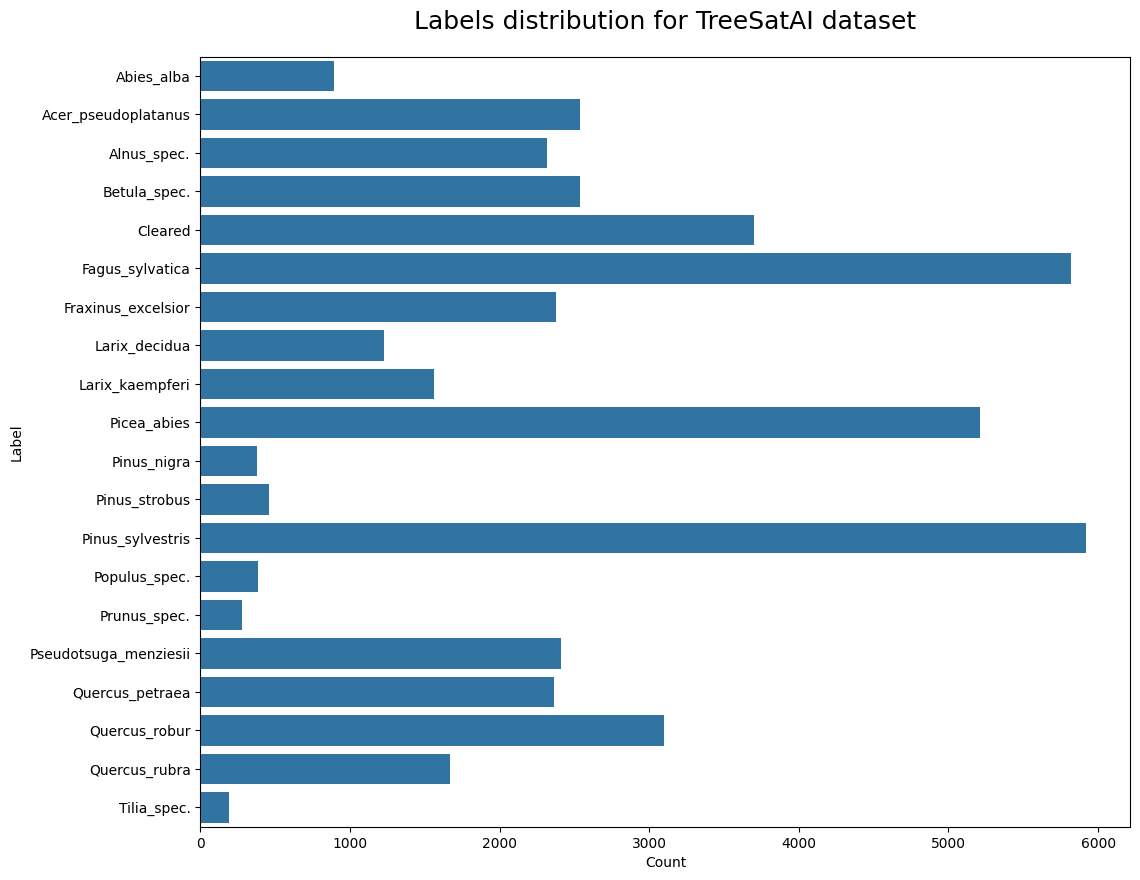

In [24]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/TreeSatAI/aerial/",
    "csv_file": "./data/TreeSatAI/train_filenames.lst",
}

train_dataset = TreeSatAIDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/TreeSatAI/aerial/",
    "csv_file": "./data/TreeSatAI/test_filenames.lst",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = TreeSatAIDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(45337, 5044)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/TreeSatAI/"
model_config = {
    "num_classes": 20, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-21 06:53:01,460 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-21 06:53:01,589 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [34]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-21 06:53:02,820 INFO Starting training.
training: 100%|██████████| 1417/1417 [20:31<00:00,  1.15it/s]
2025-05-21 07:13:35,015 INFO epoch: 1, time: 1232, loss:  1.28343
testing on train set: 100%|██████████| 1417/1417 [07:55<00:00,  2.98it/s]
2025-05-21 07:21:33,002 INFO Accuracy:0.6992302093213049, Precision Micro:0.6992302093213049, Precision Macro:0.7058324534037519, Precision Weighted:0.7151245020653905, Precision per Class:[0.87785235 0.39068994 0.5214511  0.48725687 0.83119602 0.7656574
 0.59679144 0.81076923 0.64901961 0.78902258 0.85855263 0.6130742
 0.93870082 0.66504854 0.6952381  0.80309194 0.57472284 0.62981319
 0.65203357 0.96666667], Recall Micro:0.6992302093213049, Recall Macro:0.6165560196545247, Recall Weighted:0.6992302093213049, Recall per Class:[0.73400673 0.55533675 0.71373057 0.57204724 0.85814645 0.63436426
 0.46910467 0.42915309 0.84654731 0.91845741 0.69230769 0.76096491
 0.86655405 0.35770235 0.26545455 0.81806879 0.54775993 0.53290323
 0.60587882 0.152

0.5677857305590386

## Predictions

2025-05-21 12:04:15,790 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/TreeSatAI/checkpoint.pth.tar
2025-05-21 12:04:17,416 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/TreeSatAI/checkpoint.pth.tar at epoch 11


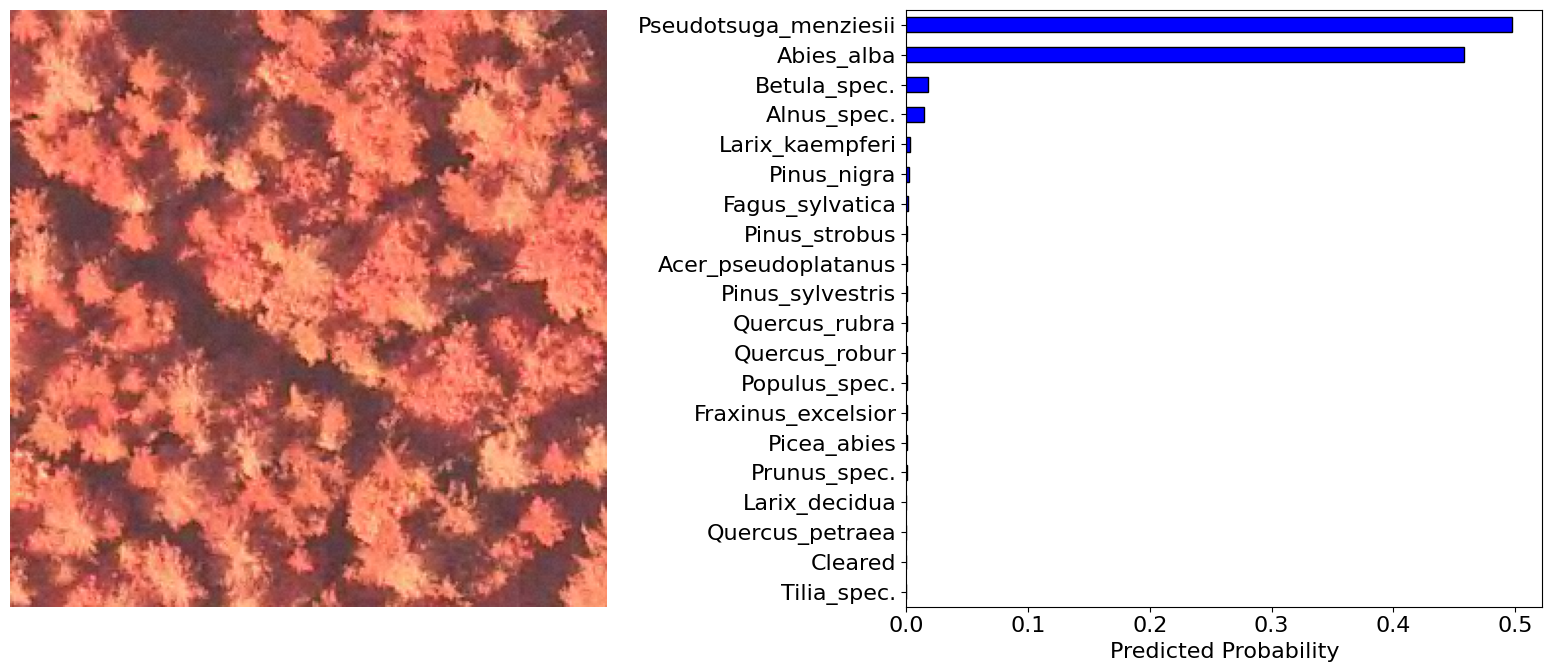

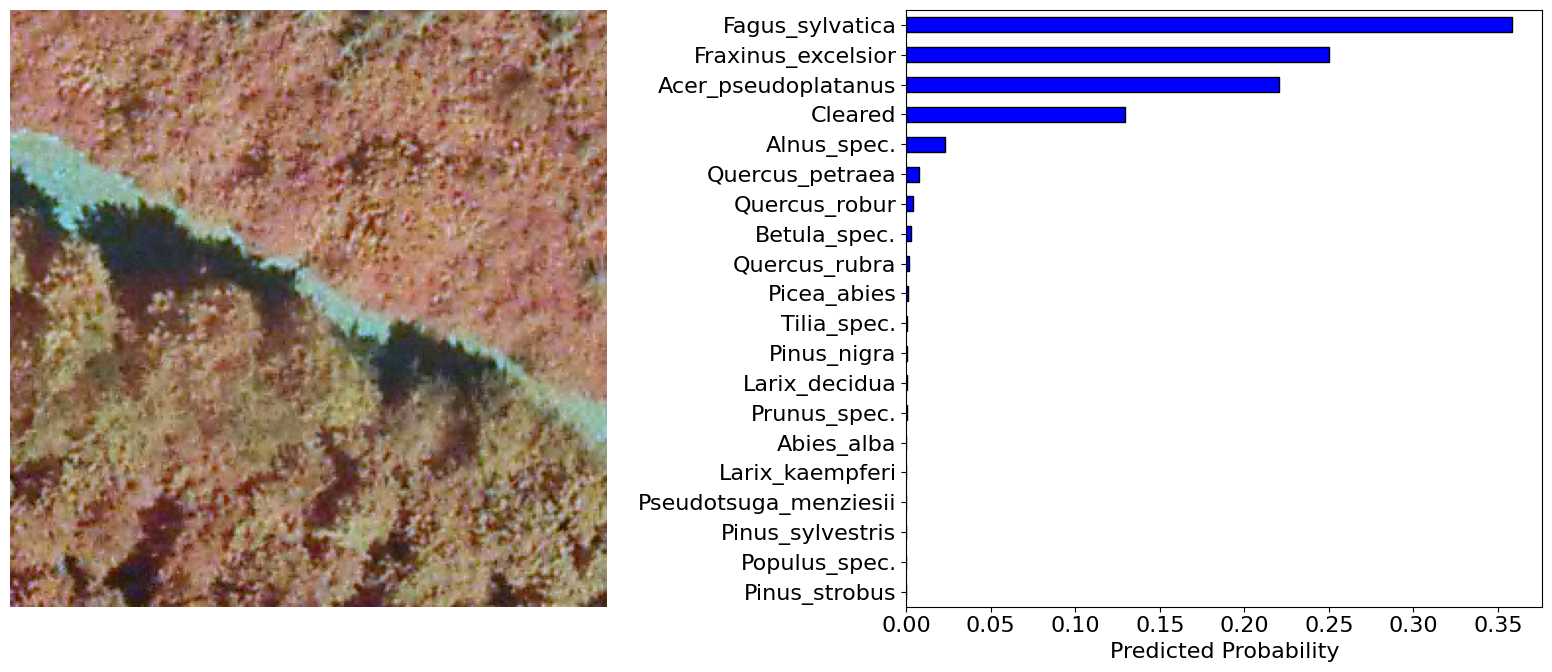

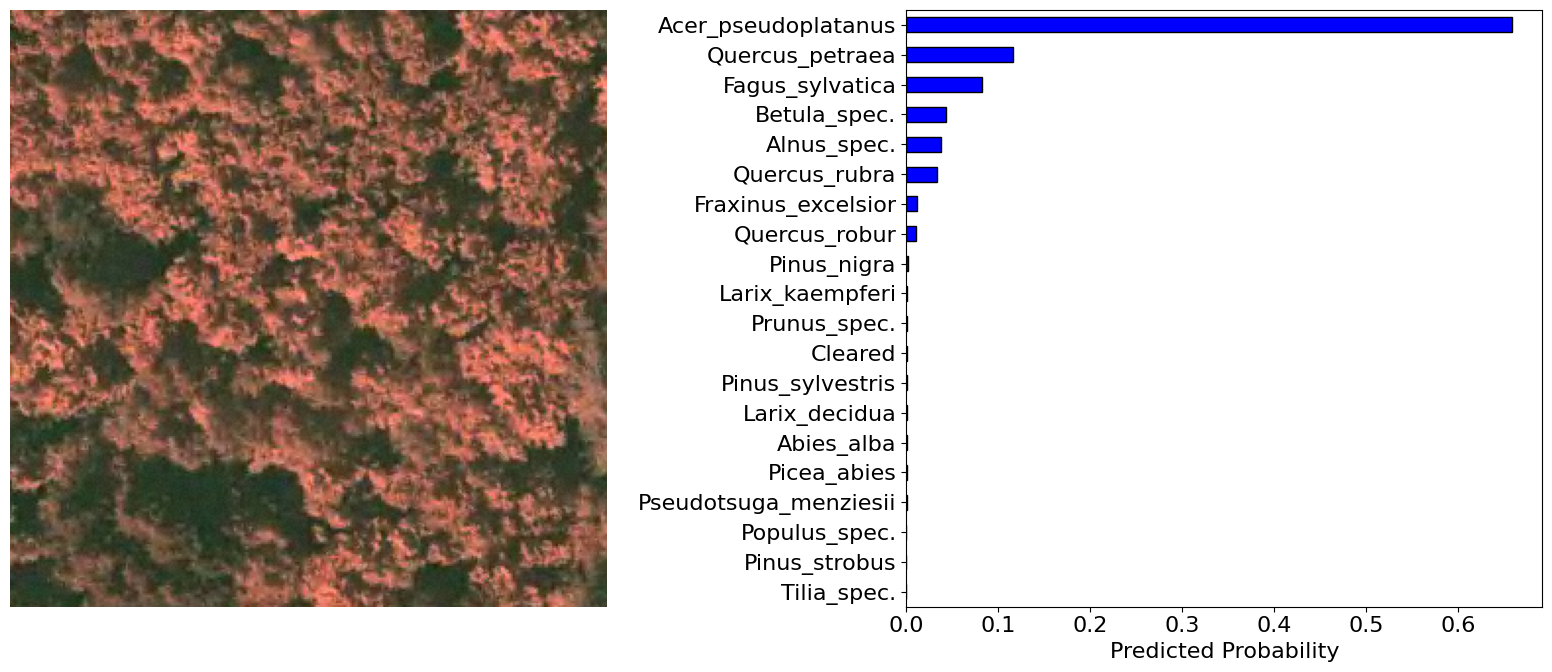

In [ ]:
labels = ["Abies_alba","Acer_pseudoplatanus","Alnus_spec.","Betula_spec.","Cleared","Fagus_sylvatica",
          "Fraxinus_excelsior","Larix_decidua","Larix_kaempferi","Picea_abies","Pinus_nigra","Pinus_strobus",
          "Pinus_sylvestris","Populus_spec.","Prunus_spec.","Pseudotsuga_menziesii","Quercus_petraea",
          "Quercus_robur","Quercus_rubra","Tilia_spec."]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/TreeSatAI/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/TreeSatAI/aerial/Abies_alba_2_339648_BI_NLF.tif')[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/TreeSatAI/aerial/Cleared_0_20386_WEFL_NLF.tif')[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/TreeSatAI/aerial/Fagus_sylvatica_3_28095_WEFL_NLF.tif')[:,:,0:3]
fig = model.predict_image(image, labels, transform)